In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("data_subset.csv", parse_dates=["date"])
df = df.sort_values(["store", "item", "date"]).reset_index(drop=True)

# Calendar features
df["month"] = df["date"].dt.month
df["dow"] = df["date"].dt.dayofweek
df["doy"] = df["date"].dt.dayofyear

# Same day last year, and its weekly average (within each store-item series)
g = df.groupby(["store", "item"])["sales"]
df["lag_364"] = g.shift(364)
df["roll_364"] = g.transform(lambda s: s.shift(364).rolling(7, min_periods=1).mean())

df = df.dropna().reset_index(drop=True)   # drops 2013 (no last-year data)
print(df.shape)
print(df["date"].min(), df["date"].max())

(73100, 9)
2013-12-31 00:00:00 2017-12-31 00:00:00


C:\Users\HP\AppData\Local\Temp\ipykernel_24840\1508204672.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["date"].dt.dayofweek
C:\Users\HP\AppData\Local\Temp\ipykernel_24840\1508204672.py:13: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["doy"] = df["date"].dt.dayofyear


In [2]:
features = ["store", "item", "month", "dow", "doy", "lag_364", "roll_364"]

train = df[df["date"] < "2017-01-01"]
test = df[df["date"] >= "2017-01-01"].copy()

print("Train:", train["date"].min().date(), "to", train["date"].max().date(), len(train))
print("Test: ", test["date"].min().date(), "to", test["date"].max().date(), len(test))

Train: 2013-12-31 to 2016-12-31 54850
Test:  2017-01-01 to 2017-12-31 18250


In [3]:
model = HistGradientBoostingRegressor(
    categorical_features=["store", "item"],
    max_iter=300,
    learning_rate=0.05,
    random_state=42,
)
model.fit(train[features], train["sales"])

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",300
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.","['store', 'item']"
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interactio

In [4]:
test["pred"] = model.predict(test[features])
test["residual"] = test["sales"] - test["pred"]

mae_model = mean_absolute_error(test["sales"], test["pred"])
mae_naive = mean_absolute_error(test["sales"], test["lag_364"])  # "same as last year"

print(f"Model MAE:          {mae_model:.2f}")
print(f"Naive baseline MAE: {mae_naive:.2f}")
print(f"Average daily sales in test: {test['sales'].mean():.2f}")

Model MAE:          6.23
Naive baseline MAE: 8.43
Average daily sales in test: 57.57


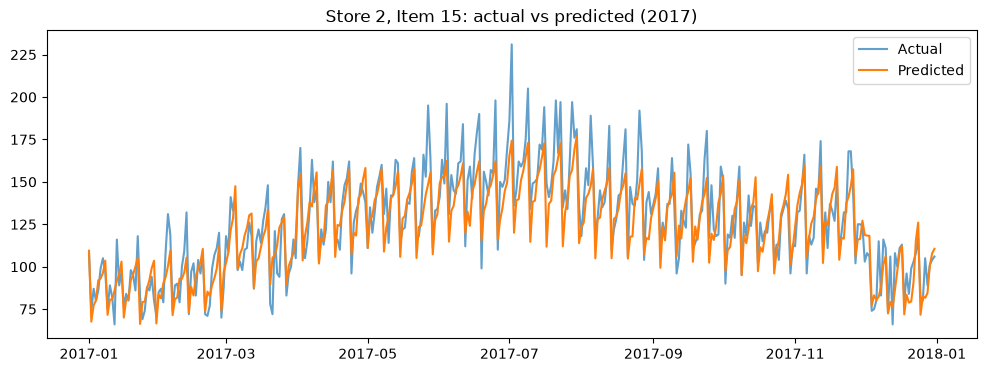

In [5]:
one = test[(test["store"] == 2) & (test["item"] == 15)]
plt.figure(figsize=(12, 4))
plt.plot(one["date"], one["sales"], label="Actual", alpha=0.7)
plt.plot(one["date"], one["pred"], label="Predicted")
plt.title("Store 2, Item 15: actual vs predicted (2017)")
plt.legend()
plt.show()

Mean residual (bias): 0.01
Residual std: 8.14


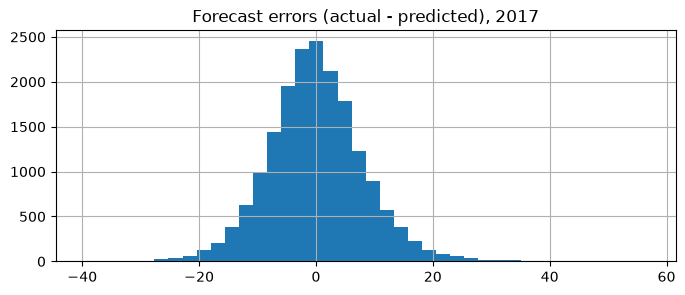

In [6]:
print("Mean residual (bias):", round(test["residual"].mean(), 2))
print("Residual std:", round(test["residual"].std(), 2))

test["residual"].hist(bins=40, figsize=(8, 3))
plt.title("Forecast errors (actual - predicted), 2017")
plt.show()

In [7]:
test[["date", "store", "item", "sales", "pred", "residual"]].to_csv(
    "forecast_2017.csv", index=False)